In [1]:
import arviz as az
import numpy as np
import pandas as pd
import pymc as pm
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import pyplot as plt
from matplotlib.cm import get_cmap
from scipy.stats import norm
import scipy.stats as stats
import matplotlib.colors as mcolors
import seaborn as sns
import xarray as xr
from datetime import datetime
from scipy.signal import find_peaks
from scipy.ndimage import label
from fastdtw import fastdtw
from collections import defaultdict
import string
import pickle
sys.path.append(os.path.abspath(".")) 
from Functions_Eps_Model_MHWdetection import *
import calendar


# Add Graphviz binaries to PATH so PyMC can find 'dot.exe'
# Adjust this path if Graphviz is installed in a different location
os.environ["PATH"] += os.pathsep + r"C:\Users\24048369\OneDrive - The University of Western Australia\Graphviz-12.2.1-win64\bin"

sys.path.append('C:/Users/24048369/OneDrive - The University of Western Australia/Desktop/Sina/marineHeatWaves-python/')
import marineHeatWavesCopy as mhw_hobday



C:\Users\24048369\AppData\Local\anaconda3\Lib\site-packages\arviz\__init__.py:39: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(
WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.


In [2]:
RANDOM_SEED = 8929
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-darkgrid")

plt.rcParams.update(
    {
        "figure.figsize": (14, 4),
        "figure.dpi": 144,
        "figure.constrained_layout.use": True,
        "axes.grid": True,
        "grid.linewidth": 0.5,
        "grid.linestyle": "--",
        "axes.spines.top": False,
        "axes.spines.bottom": False,
        "axes.spines.left": False,
        "axes.spines.right": False,
    }
)


def sampler_kwargs():
    return dict(
        nuts_sampler="nutpie",
        chains=4,
        draws=500,
        nuts_sampler_kwargs={"backend": "jax", "gradient_backend": "jax"},
    )


current_folder = os.getcwd()
# Define the folder name where figures will be saved
file_folder = os.path.join(f'{current_folder}') #current_folder, "Autoregressive_original_ARvsEPS_daily_short")
Folder_name = 'Figures'

figures_folder = os.path.join(f'{current_folder}\\{Folder_name}')#current_folder, "Autoregressive_original_ARvsEPS_daily_short")
# Create the folder if it does not exist
os.makedirs(figures_folder, exist_ok=True)
os.makedirs(file_folder, exist_ok=True)
print(f"Figures will be saved in: {figures_folder}")
print(f"Files are in: {file_folder}")


Figures will be saved in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection\Figures
Files are in: C:\Users\24048369\OneDrive - The University of Western Australia\Paper2_Github\pymc_MHWdetection


## these are the names of the 4 different stations and the date of interests (MHW events) 


In [3]:
# your sites and subsets
sites = ["Japan", "NorthWestShelf", "SouthWA", "UK"]
subsets = ["3", "5", "7", "12", "30"]
hemis = ['NH', 'SH','SH','NH']

date_of_interest = {
    "Japan": "2024-08-01",
    "NorthWestShelf": "2004-12-15",
    "SouthWA": "2011-03-01",
    "UK": "2013-07-30",
}

## Loook At Specific Summers


In [4]:
event_windows = {
    "Japan": ("2024-07-01", "2024-12-31"),          # boreal summer 2025
    "UK": ("2013-06-01", "2013-12-31"),             # summer 2013
    "SouthWA": ("2010-10-01", "2011-06-30"),        # austral summer 2010/2011
    "NorthWestShelf": ("2004-10-01", "2005-06-30")  # austral summer 2004/2005
}

 # if containment == "within":
 #        mask = (ds >= start) & (de <= end)



def filter_events(mhw_dict, start, end):
    """Return events from mhw_dict that overlap with given window."""
    starts = pd.to_datetime(mhw_dict["date_start"])
    ends = pd.to_datetime(mhw_dict["date_end"])

    mask = (starts >= pd.to_datetime(start)) & (ends <= pd.to_datetime(end))
    return {k: np.array(v)[mask] for k, v in mhw_dict.items() if isinstance(v, list)}

def summarize_event(mhw_dict,method):
    if len(mhw_dict["date_start"]) == 0:
        return {"n_events": 0}

    return {
        "start": str(pd.to_datetime(mhw_dict["date_start"][0]).date()),
        "end": str(pd.to_datetime(mhw_dict["date_end"][-1]).date()),
        "n_events": int(len(mhw_dict["date_end"])),
        "mean_intensity50": round(np.mean(mhw_dict["intensity_mean"]),  2),
        "max_intensity50": round(np.max(mhw_dict["intensity_max"]),  2),
        "cumulative_intensity50": round(np.sum(mhw_dict["intensity_cumulative"]),  2),
        "total_duration": int(np.sum(mhw_dict["duration"])),
        "method": method
    }


def summarize_event_hps(mhw_dict):
    if len(mhw_dict["date_start"]) == 0:
        return {"n_events": 0}

    return {
        "start": str(pd.to_datetime(mhw_dict["date_start"][0]).date()),
        "end": str(pd.to_datetime(mhw_dict["date_end"][-1]).date()),
        "n_events": int(len(mhw_dict["date_end"])),
        "mean_intensity01": round(np.mean(mhw_dict["intensity_mean_p1"]), 2),
        "mean_intensity50": round(np.mean(mhw_dict["intensity_mean_p50"]), 2),
        "mean_intensity99": round(np.mean(mhw_dict["intensity_mean_p99"]), 2),
        "max_intensity01": round(np.max(mhw_dict["intensity_max_p1"]), 2),
        "max_intensity50": round(np.max(mhw_dict["intensity_max_p50"]), 2),
        "max_intensity99": round(np.max(mhw_dict["intensity_max_p99"]), 2),
        "cumulative_intensity01": round(np.sum(mhw_dict["intensity_cumulative_p1"]), 2),
        "cumulative_intensity50": round(np.sum(mhw_dict["intensity_cumulative_p50"]), 2),
        "cumulative_intensity99": round(np.sum(mhw_dict["intensity_cumulative_p99"]), 2),
        "total_duration": int(np.sum(mhw_dict["duration"])),
        "method": 'PyMC'
    }


def compare_methods(site, event_windows, mhw_dict_hobday_full,  mhw_dict_hps): #mhw_dict_hobday_sub
    start, end = event_windows[site]

    hobday_full_event = filter_events(mhw_dict_hobday_full, start, end)
    # hobday_sub_event  = filter_events(mhw_dict_hobday_sub, start, end)
    hps_event         = filter_events(mhw_dict_hps, start, end)

    summary = {
        "Hobday_full": summarize_event(hobday_full_event, 'Full 30yrs'),
        # "Hobday_sub": summarize_event(hobday_sub_event, 'Subset'),
        "PyMC": summarize_event_hps(hps_event),
    }

    df = pd.DataFrame(summary).T  # methods as rows
    df.index.name = "Method"
    return df


In [6]:
all_metrics = []
for i, site in enumerate(sites[:]):

    # day_of_interest  = date_of_interest[site]
    
    output_dir_site = os.path.join(figures_folder, site)

    # load Hobday climatology (30yrs reference)
    hobday = pd.read_csv( os.path.join(output_dir_site, "Daily_Hobday.csv"),index_col=0, parse_dates=True)
    mhw_dict_hobday_full = np.load(f"{output_dir_site}/30years_mhw_dict.npy",allow_pickle='TRUE').item()


    selected_date = date_of_interest[site]
    
    
    
    for sub in subsets[:]:
        
            
        # load your OG timeseries for this subset
        og_timeseries = pd.read_pickle(f"{output_dir_site}/df_C_roll_{sub}yrs.pkl")

        # load inference data for this subset
        idata = az.from_netcdf(os.path.join(output_dir_site, f"Idata_eps_{sub}yrs.nc"))


        # calculate PCR & PTR and HPS
        pcr, ptr, time_array = get_PCRs_and_PTR(idata, og_timeseries)
        prob_PTR = calculate_prob_PTR(og_timeseries, ptr, variable="Temp")
        T_obs = og_timeseries.Temp
        HPS = np.array(prob_PTR)

        # crop hobday to same period as og_timeseries
        hobday_sub = hobday.loc[og_timeseries.index.min(): og_timeseries.index.max()]


        mhw_dict_hps = detect_mhws_from_hps(HPS=np.array(prob_PTR),T_obs=og_timeseries.Temp,PCR=pcr, PTR=ptr , 
                                            time=og_timeseries.index,detection_threshold=50,ramp_threshold=20, 
                                            max_dip=10,min_duration=10)

        


        ## short term MHW edictinary from short obserevered SST
        # mhw_dict_hobday_sub,_,_ = comparing_to_Hobday(T_obs)   



        # pick event window for this site
        # start, end = event_windows[site]

        df = compare_methods(site, event_windows, mhw_dict_hobday_full, mhw_dict_hps) #mhw_dict_hobday_sub
        df['sub'] = sub
        df['site'] = site
        all_metrics.append(df)


    

all_metrics = pd.concat(all_metrics, ignore_index=True)

C:\Users\24048369\AppData\Local\Temp\ipykernel_28776\60585126.py:169: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


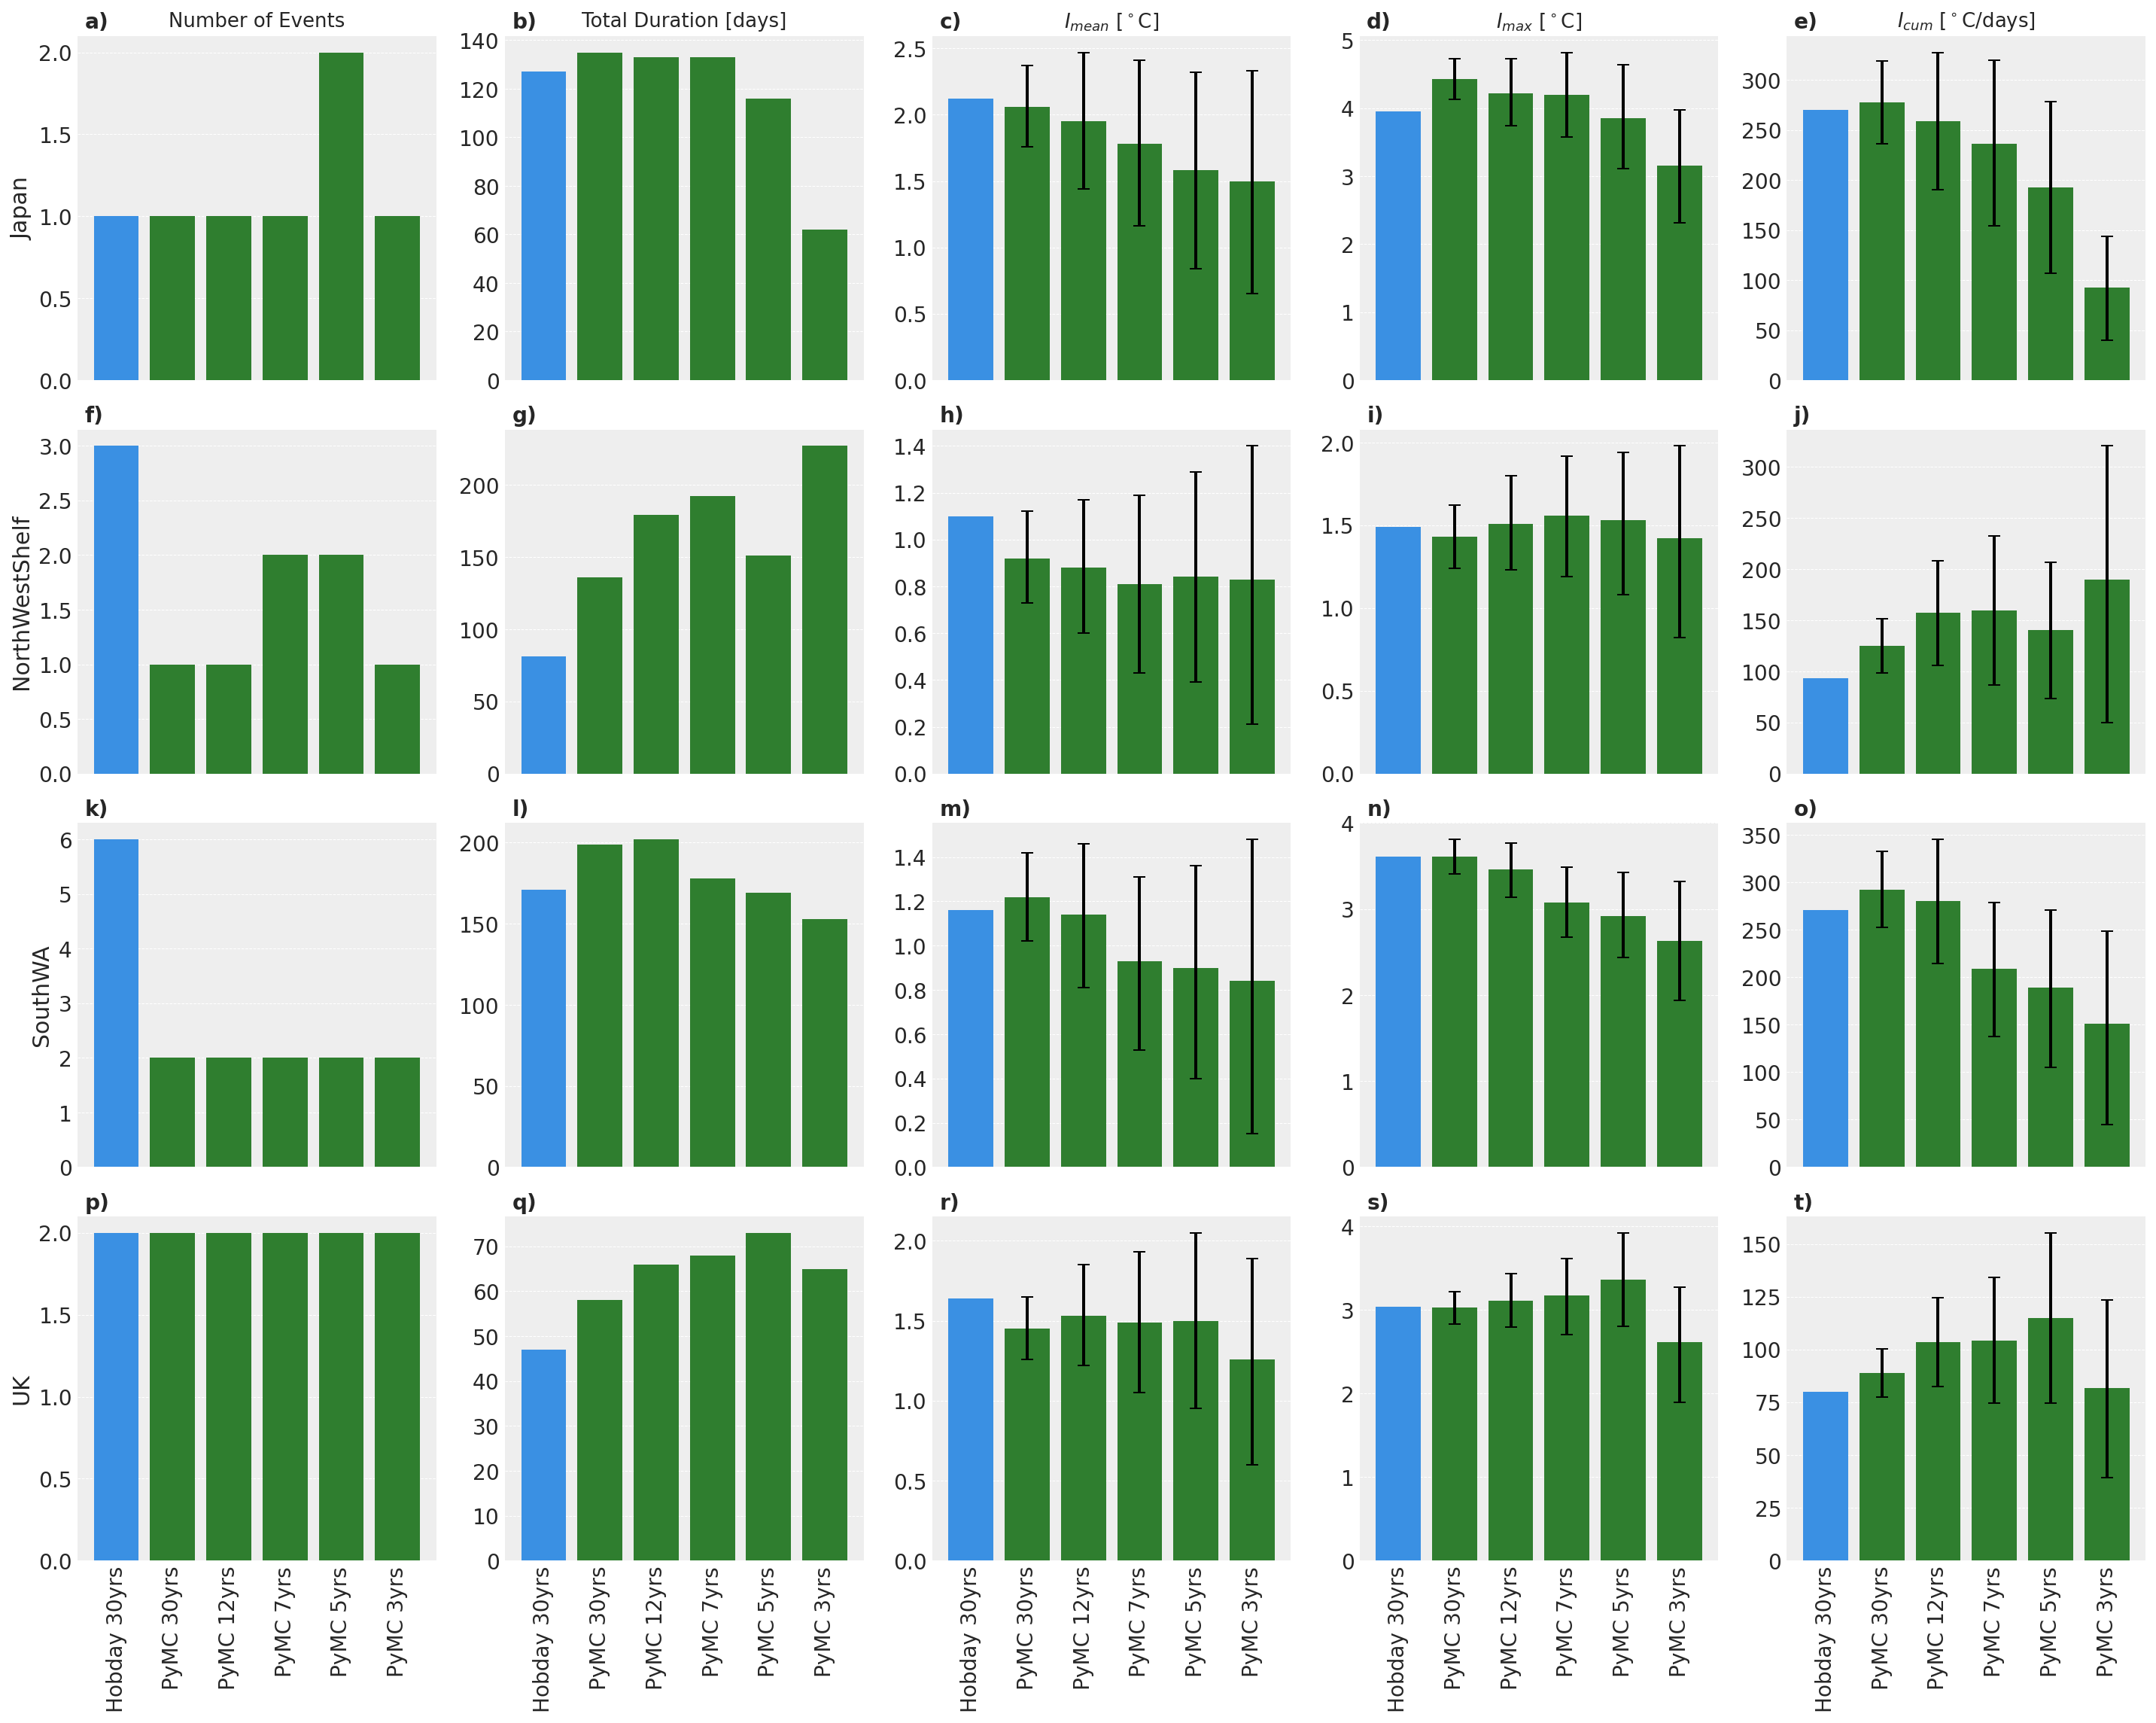

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import string
import os

# ============================
# 1. Example dataframe
# ============================
# (replace this with your loaded all_metrics df)
# all_metrics = pd.read_csv("your_file.csv")

# ============================
# 2. Melt into long form
# ============================
df_melted = all_metrics.melt(
    id_vars=["site", "method", "sub"],
    value_vars=[
        "n_events", "total_duration",
        "mean_intensity50", "max_intensity50", "cumulative_intensity50",
        "mean_intensity01", "max_intensity01", "cumulative_intensity01",
        "mean_intensity99", "max_intensity99", "cumulative_intensity99"
    ],
    var_name="metric",
    value_name="value"
)

# ============================
# 3. Define pretty labels
# ============================
metric_labels = {
    "n_events": "Number of Events",
    "total_duration": "Total Duration [days]",
    "mean_intensity50": r"$I_{mean}$ [$^\circ$C]",
    "max_intensity50": r"$I_{max}$ [$^\circ$C]",
    "cumulative_intensity50": r"$I_{cum}$ [$^\circ$C/days]",
    "mean_intensity01": r"$I_{mean}$ 0.01",
    "mean_intensity99": r"$I_{mean}$ 0.99",
    "max_intensity01": r"$I_{max}$ 0.01",
    "max_intensity99": r"$I_{max}$ 0.99",
    "cumulative_intensity01": r"$I_{cum}$ 0.01",
    "cumulative_intensity99": r"$I_{cum}$ 0.99",
}
df_melted["metric"] = df_melted["metric"].map(metric_labels)

# ============================
# 4. Drop duplicates (safety)
# ============================
df_melted_unique = df_melted.drop_duplicates(
    subset=["site", "metric", "method", 'sub',"value"]
)

# ============================
# 5. Create label column
# ============================
def make_label(row):
    if row["method"] == "Full 30yrs":
        return "Hobday 30yrs"
    else:
        return f"{row['method']} {row['sub']}yrs"

df_melted_unique["method_subset"] = df_melted_unique.apply(make_label, axis=1)

# ============================
# 6. Define metric order
# ============================
metric_order = [
    "Number of Events",
    "Total Duration [days]",
    r"$I_{mean}$ [$^\circ$C]",
    r"$I_{max}$ [$^\circ$C]",
    r"$I_{cum}$ [$^\circ$C/days]"
]

# Which need error bars
intensity_metrics = {
    r"$I_{mean}$ [$^\circ$C]": "mean_intensity",
    r"$I_{max}$ [$^\circ$C]": "max_intensity",
    r"$I_{cum}$ [$^\circ$C/days]": "cumulative_intensity"
}

# ============================
# 7. Plot per site
# ============================
sites = df_melted_unique["site"].unique()
fig, axes = plt.subplots(
    nrows=len(sites), ncols=len(metric_order),
    figsize=(4*len(metric_order), 4*len(sites)),
    sharey=False, sharex=True
)

if len(sites) == 1:
    axes = np.array([axes])  # make consistent

for f, (site, site_df) in enumerate(df_melted_unique.groupby("site")):
    
    for ax, metric in zip(axes[f,:], metric_order):
        
        metric_df = site_df[site_df["metric"] == metric]
        metric_df = metric_df[::-1]
        metric_df.iloc[0], metric_df.iloc[1] = metric_df.iloc[1].copy(), metric_df.iloc[0].copy()

        # --- Plot baseline bars ---
        sns.barplot(
            data=metric_df,
            x="method_subset",
            y="value",
            ax=ax,
            hue="method",
            palette=['dodgerblue','forestgreen'],
            legend=False
        )

        # --- Add error bars for intensity metrics ---
        if metric in intensity_metrics.keys():
            base = intensity_metrics[metric]
            
            df50    = all_metrics[(all_metrics["site"] == site) & (all_metrics["method"] == "PyMC")][["sub", f"{base}50"]]
            df01_99 = all_metrics[(all_metrics["site"] == site) & (all_metrics["method"] == "PyMC")][["sub", f"{base}01", f"{base}99"]]
            
            merged = df50.merge(df01_99, on="sub", how="inner")
            merged = merged[::-1]
            
            y = merged[f"{base}50"].values
            yerr_lower =  merged[f"{base}01"].values - y
            yerr_upper =  y - merged[f"{base}99"].values
            
            x_positions = range(1, len(merged)+1)
            ax.errorbar(
                x=x_positions,
                y=y,
                yerr=[yerr_lower, yerr_upper],
                fmt="none",
                ecolor="black",
                elinewidth=2,
                capsize=4,
                zorder=10)


        

        # formatting
        if ax == axes[f,0]:
            ax.set_ylabel(f"{site}", fontsize=15)
        else:
            ax.set_ylabel("", fontsize=11)

        if f == 0:
            ax.set_title(metric, fontsize=13)
        else:
            ax.set_title("", fontsize=14)
        
        ax.set_xlabel("", fontsize=11)
        ax.tick_params(axis="x", rotation=90)

# ============================
# 8. Subplot labels
# ============================
labels = [f"{ch})" for ch in string.ascii_lowercase[:len(axes.flat)]]
for ax, lab in zip(axes.flat, labels):
    ax.text(0.02, 1.07, lab,
            transform=ax.transAxes,
            fontsize=14,
            fontweight='bold',
            va='top', ha='left',
            bbox=dict(facecolor='white', alpha=0.0, edgecolor='none', pad=0))

plt.tight_layout()

# ============================
# 9. Save figures
# ============================
# plt.savefig(os.path.join(figures_folder, "Figure_09.pdf"), dpi=100, bbox_inches="tight")
# plt.savefig(os.path.join(figures_folder, "Figure_09.png"), dpi=300, bbox_inches="tight")
plt.show()

In [18]:
all_metrics

,start,end,n_events,mean_intensity50,max_intensity50,cumulative_intensity50,total_duration,method,mean_intensity01,mean_intensity99,max_intensity01,max_intensity99,cumulative_intensity01,cumulative_intensity99,sub,site
0,2024-07-19,2024-11-22,1,2.12,3.95,269.82,127,Full 30yrs,NaN,NaN,NaN,NaN,NaN,NaN,3,Japan
1,2024-07-18,2024-09-17,1,1.5,3.15,92.85,62,PyMC,2.35,0.67,3.99,2.33,145.67,41.65,3,Japan
2,2024-07-19,2024-11-22,1,2.12,3.95,269.82,127,Full 30yrs,NaN,NaN,NaN,NaN,NaN,NaN,5,Japan
3,2024-07-16,2024-11-23,2,1.58,3.85,192.35,116,PyMC,2.32,0.84,4.59,3.06,278.04,106.46,5,Japan
4,2024-07-19,2024-11-22,1,2.12,3.95,269.82,127,Full 30yrs,NaN,NaN,NaN,NaN,NaN,NaN,7,Japan
5,2024-07-13,2024-11-22,1,1.78,4.2,236.51,133,PyMC,2.4,1.15,4.82,3.58,318.58,153.44,7,Japan
6,2024-07-19,2024-11-22,1,2.12,3.95,269.82,127,Full 30yrs,NaN,NaN,NaN,NaN,NaN,NaN,12,Japan
7,2024-07-14,2024-11-23,1,1.95,4.22,258.72,133,PyMC,2.46,1.43,4.7,3.71,327.22,189.82,12,Japan
8,2024-07-19,2024-11-22,1,2.12,3.95,269.82,127,Full 30yrs,NaN,NaN,NaN,NaN,NaN,NaN,30,Japan
9,2024-07-12,2024-11-23,1,2.06,4.43,277.75,135,PyMC,2.36,1.75,4.73,4.13,318.9,236.39,30,Japan


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Melt your all_metrics into long form ---
df_melted = all_metrics.melt(
    id_vars=["site", "method", "sub"],
    value_vars=["n_events", "total_duration", "mean_intensity50", "max_intensity50", "cumulative_intensity50",
                                                "mean_intensity01", "max_intensity01", "cumulative_intensity01",
                                                "mean_intensity99", "max_intensity99", "cumulative_intensity99"],
    var_name="metric",
    value_name="value"
)

np.unique(df_melted.metric)
df_melted


# --- 2. Define nice labels ---
metric_labels = {
    "n_events": "Number of Events",
    "total_duration": "Total Duration [days]",
    "mean_intensity50": r"$I_{mean}$ [$^\circ$C]",
    "max_intensity50": r"$I_{max}$ [$^\circ$C]",
    "cumulative_intensity50": r"$I_{cum}$ [$^\circ$C/days]"
}
df_melted["metric"] = df_melted["metric"].map(metric_labels)

# --- 3. Keep only ONE 30yrs Hobday entry per site ---
# (assumes duplicates exist in your all_metrics)
df_melted_unique = df_melted.drop_duplicates(
    subset=["site", "metric", "method",  "value"]
)

df_melted_unique#.metric

,site,method,sub,metric,value
0,Japan,Full 30yrs,3,Number of Events,1
1,Japan,PyMC,3,Number of Events,1
3,Japan,PyMC,5,Number of Events,2
10,NorthWestShelf,Full 30yrs,3,Number of Events,3
11,NorthWestShelf,PyMC,3,Number of Events,1
...,...,...,...,...,...
431,UK,PyMC,3,NaN,40.28
433,UK,PyMC,5,NaN,74.59
435,UK,PyMC,7,NaN,74.36
437,UK,PyMC,12,NaN,82.39


## MHW Detectoin Timeseries 

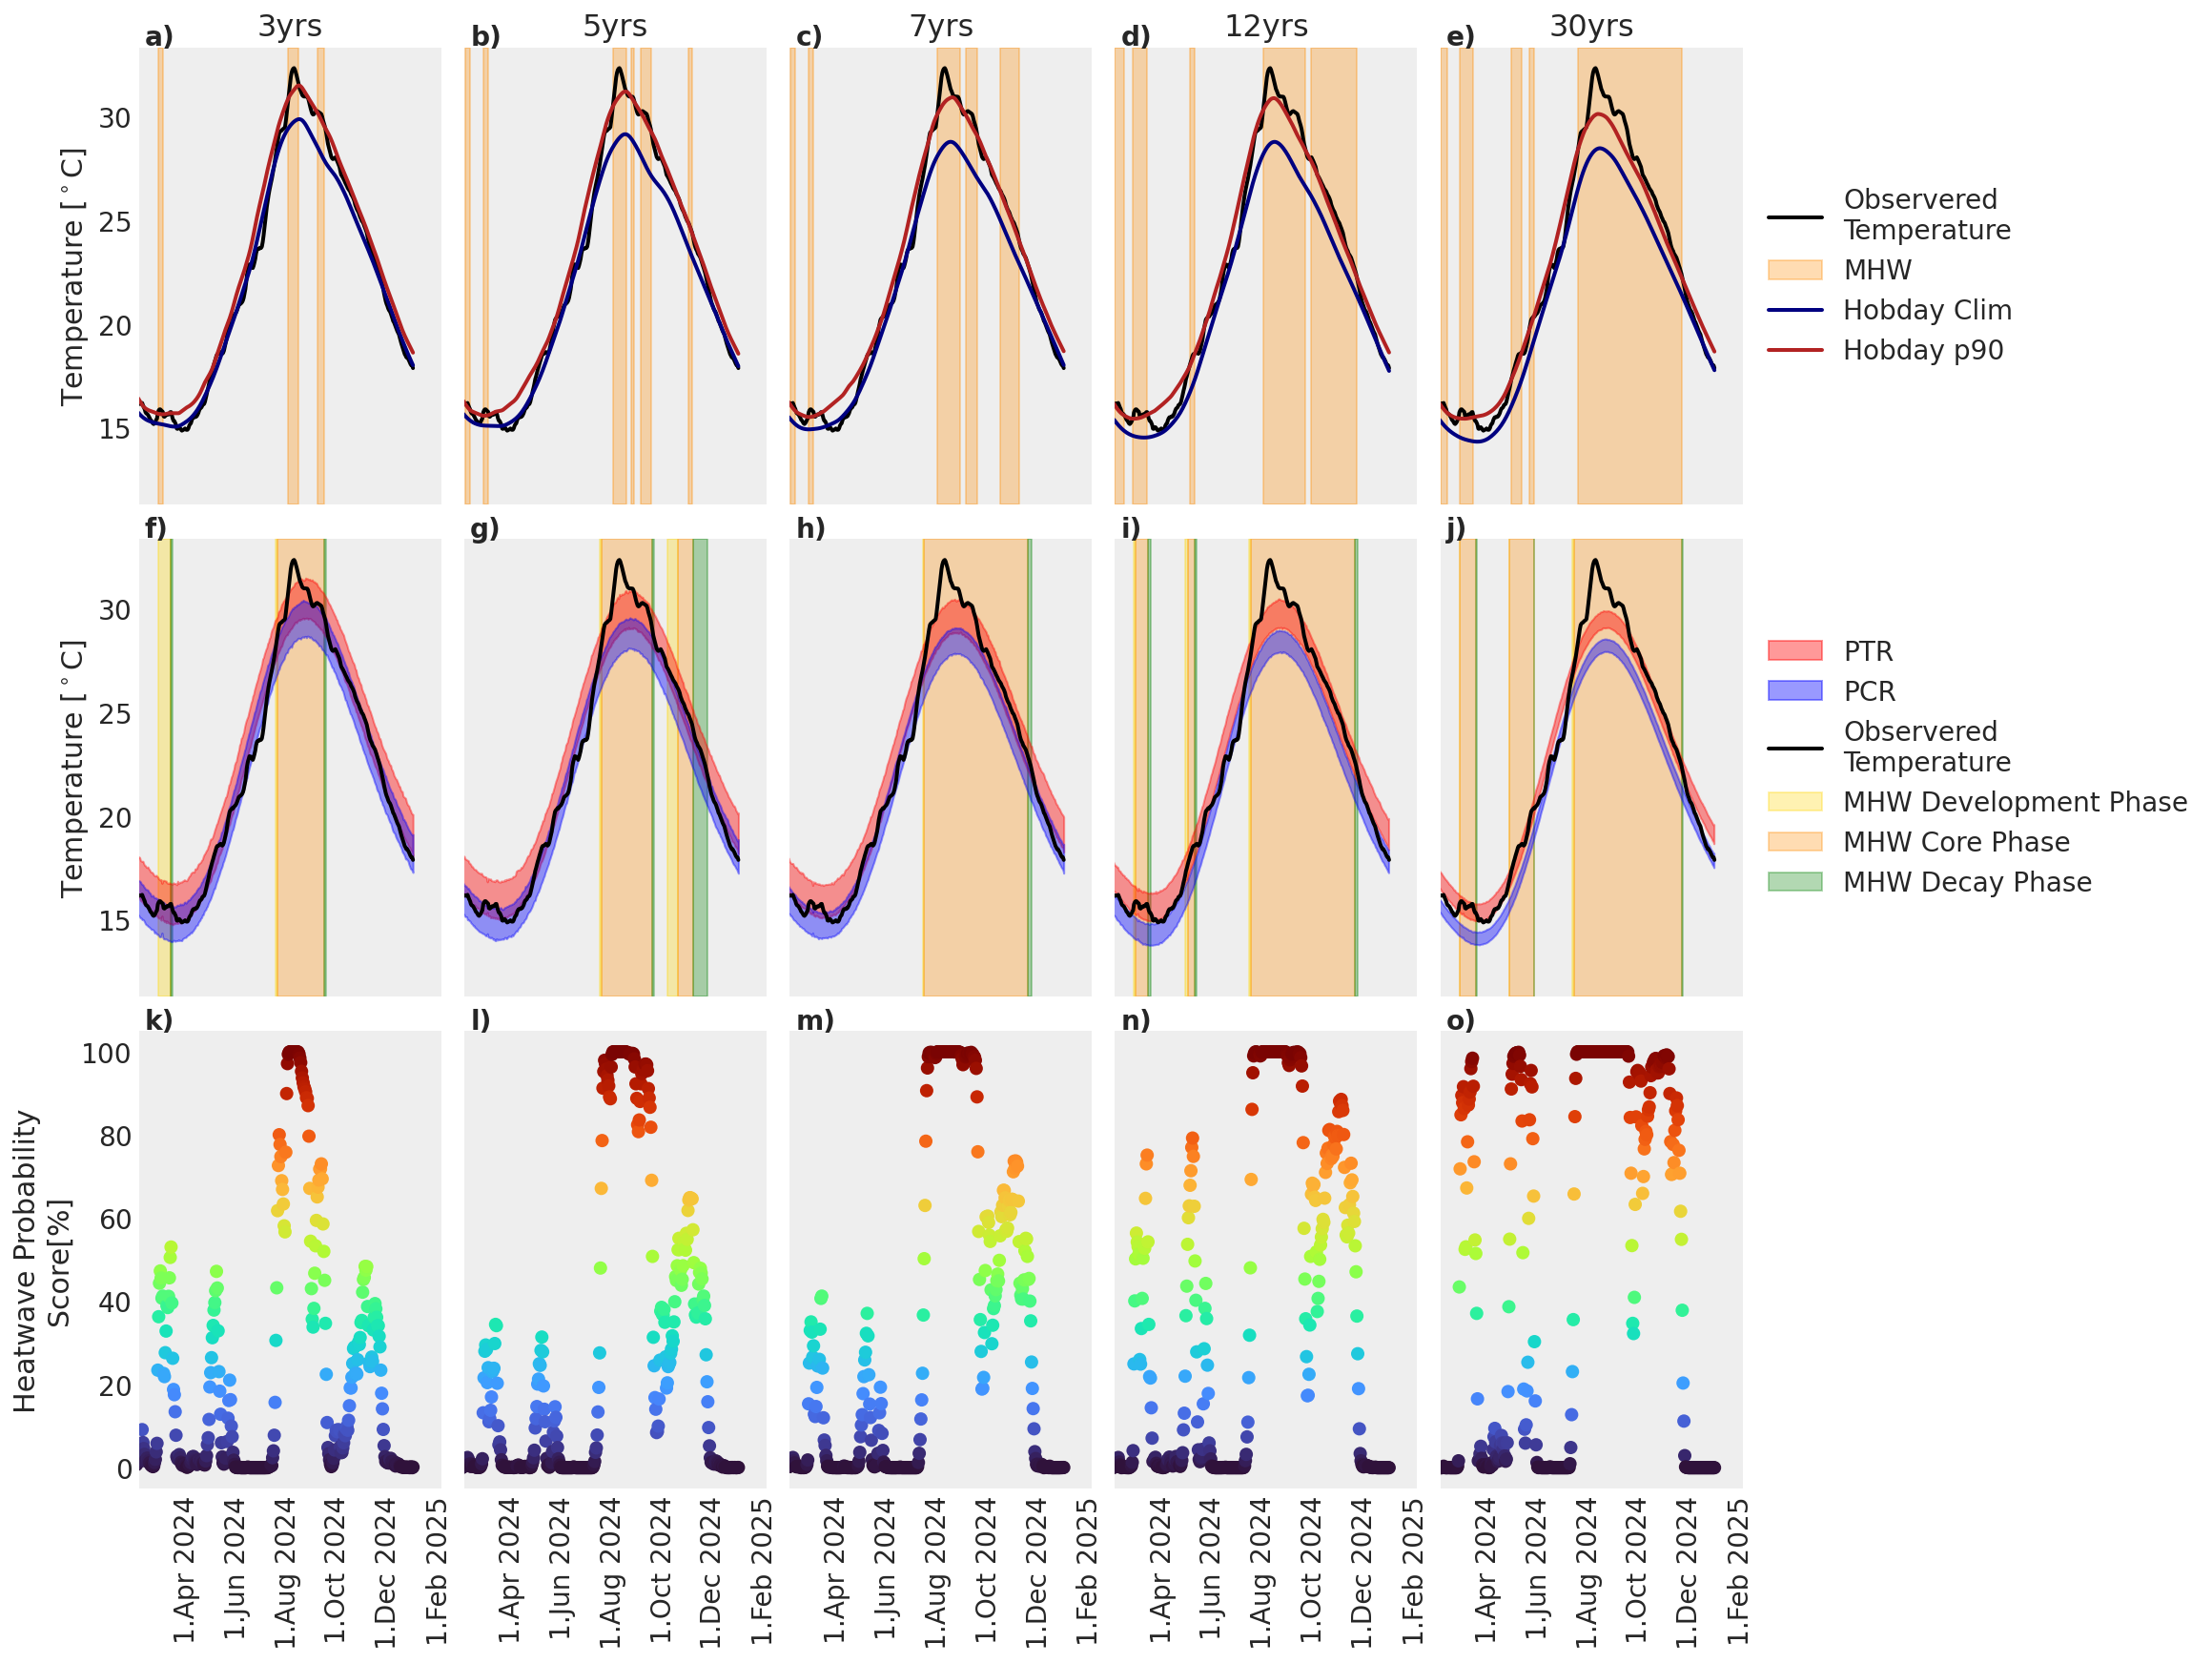

From 2024-02-03 to 2025-02-03


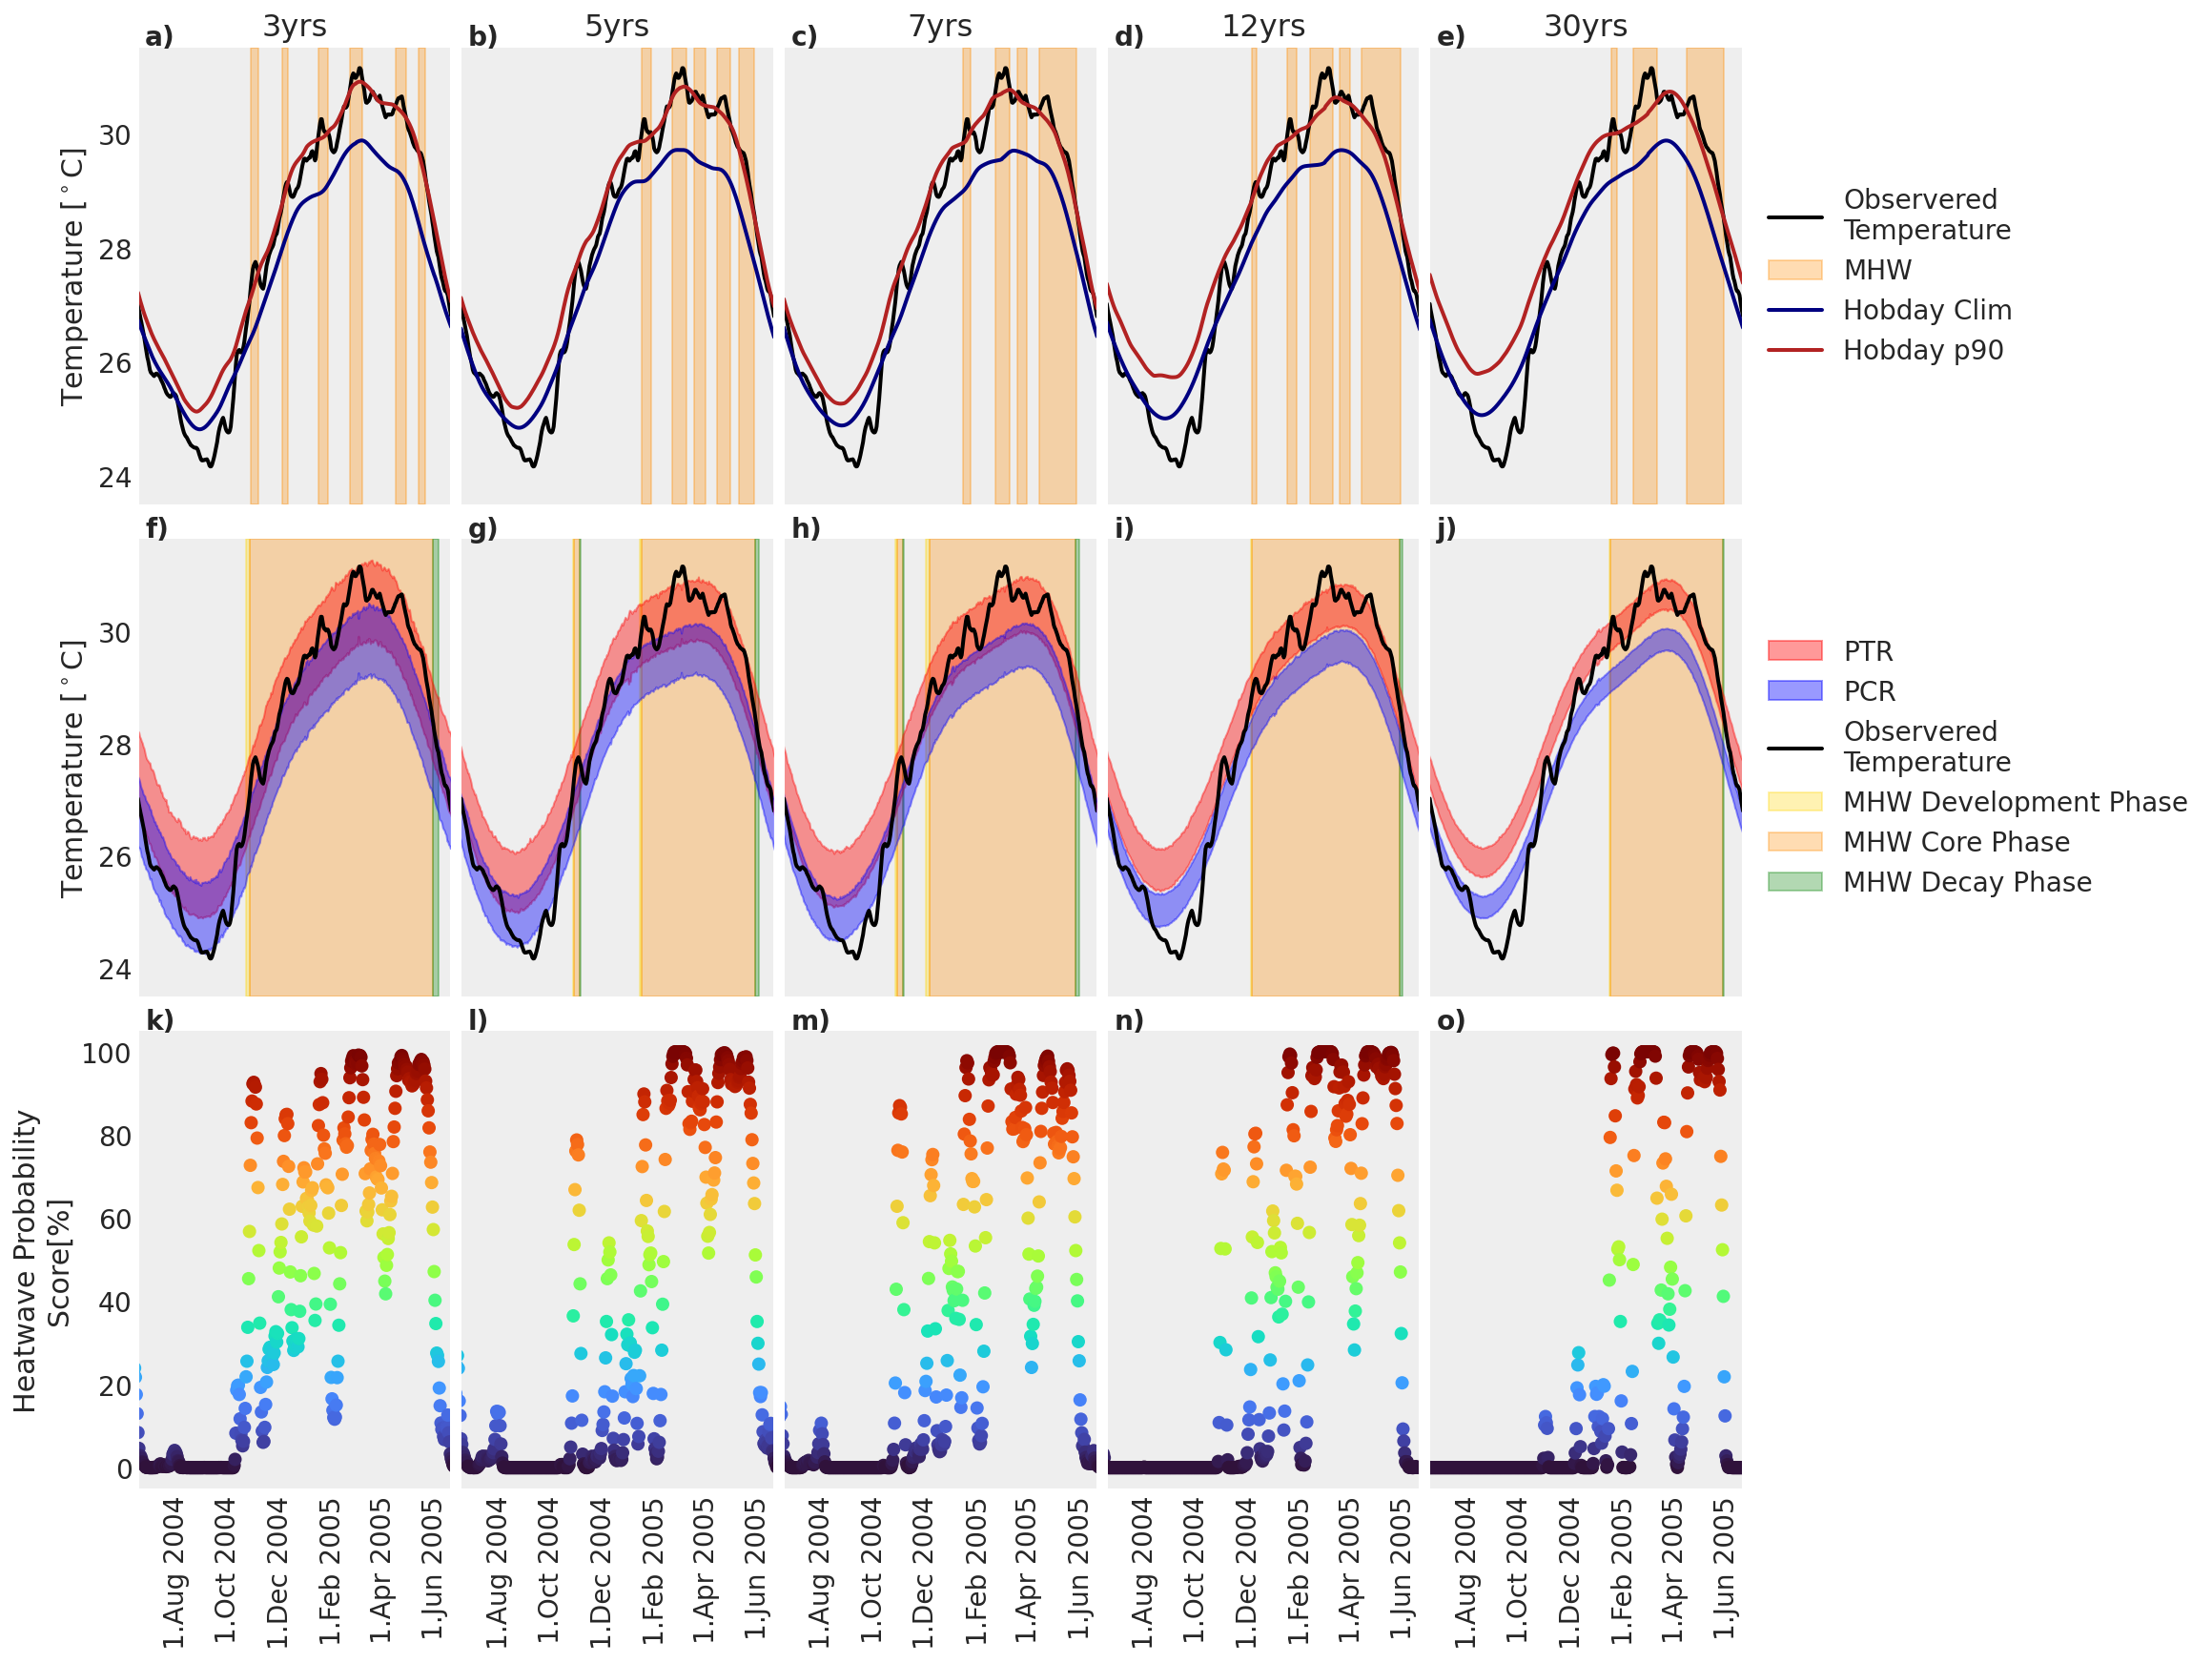

From 2004-06-18 to 2005-06-19


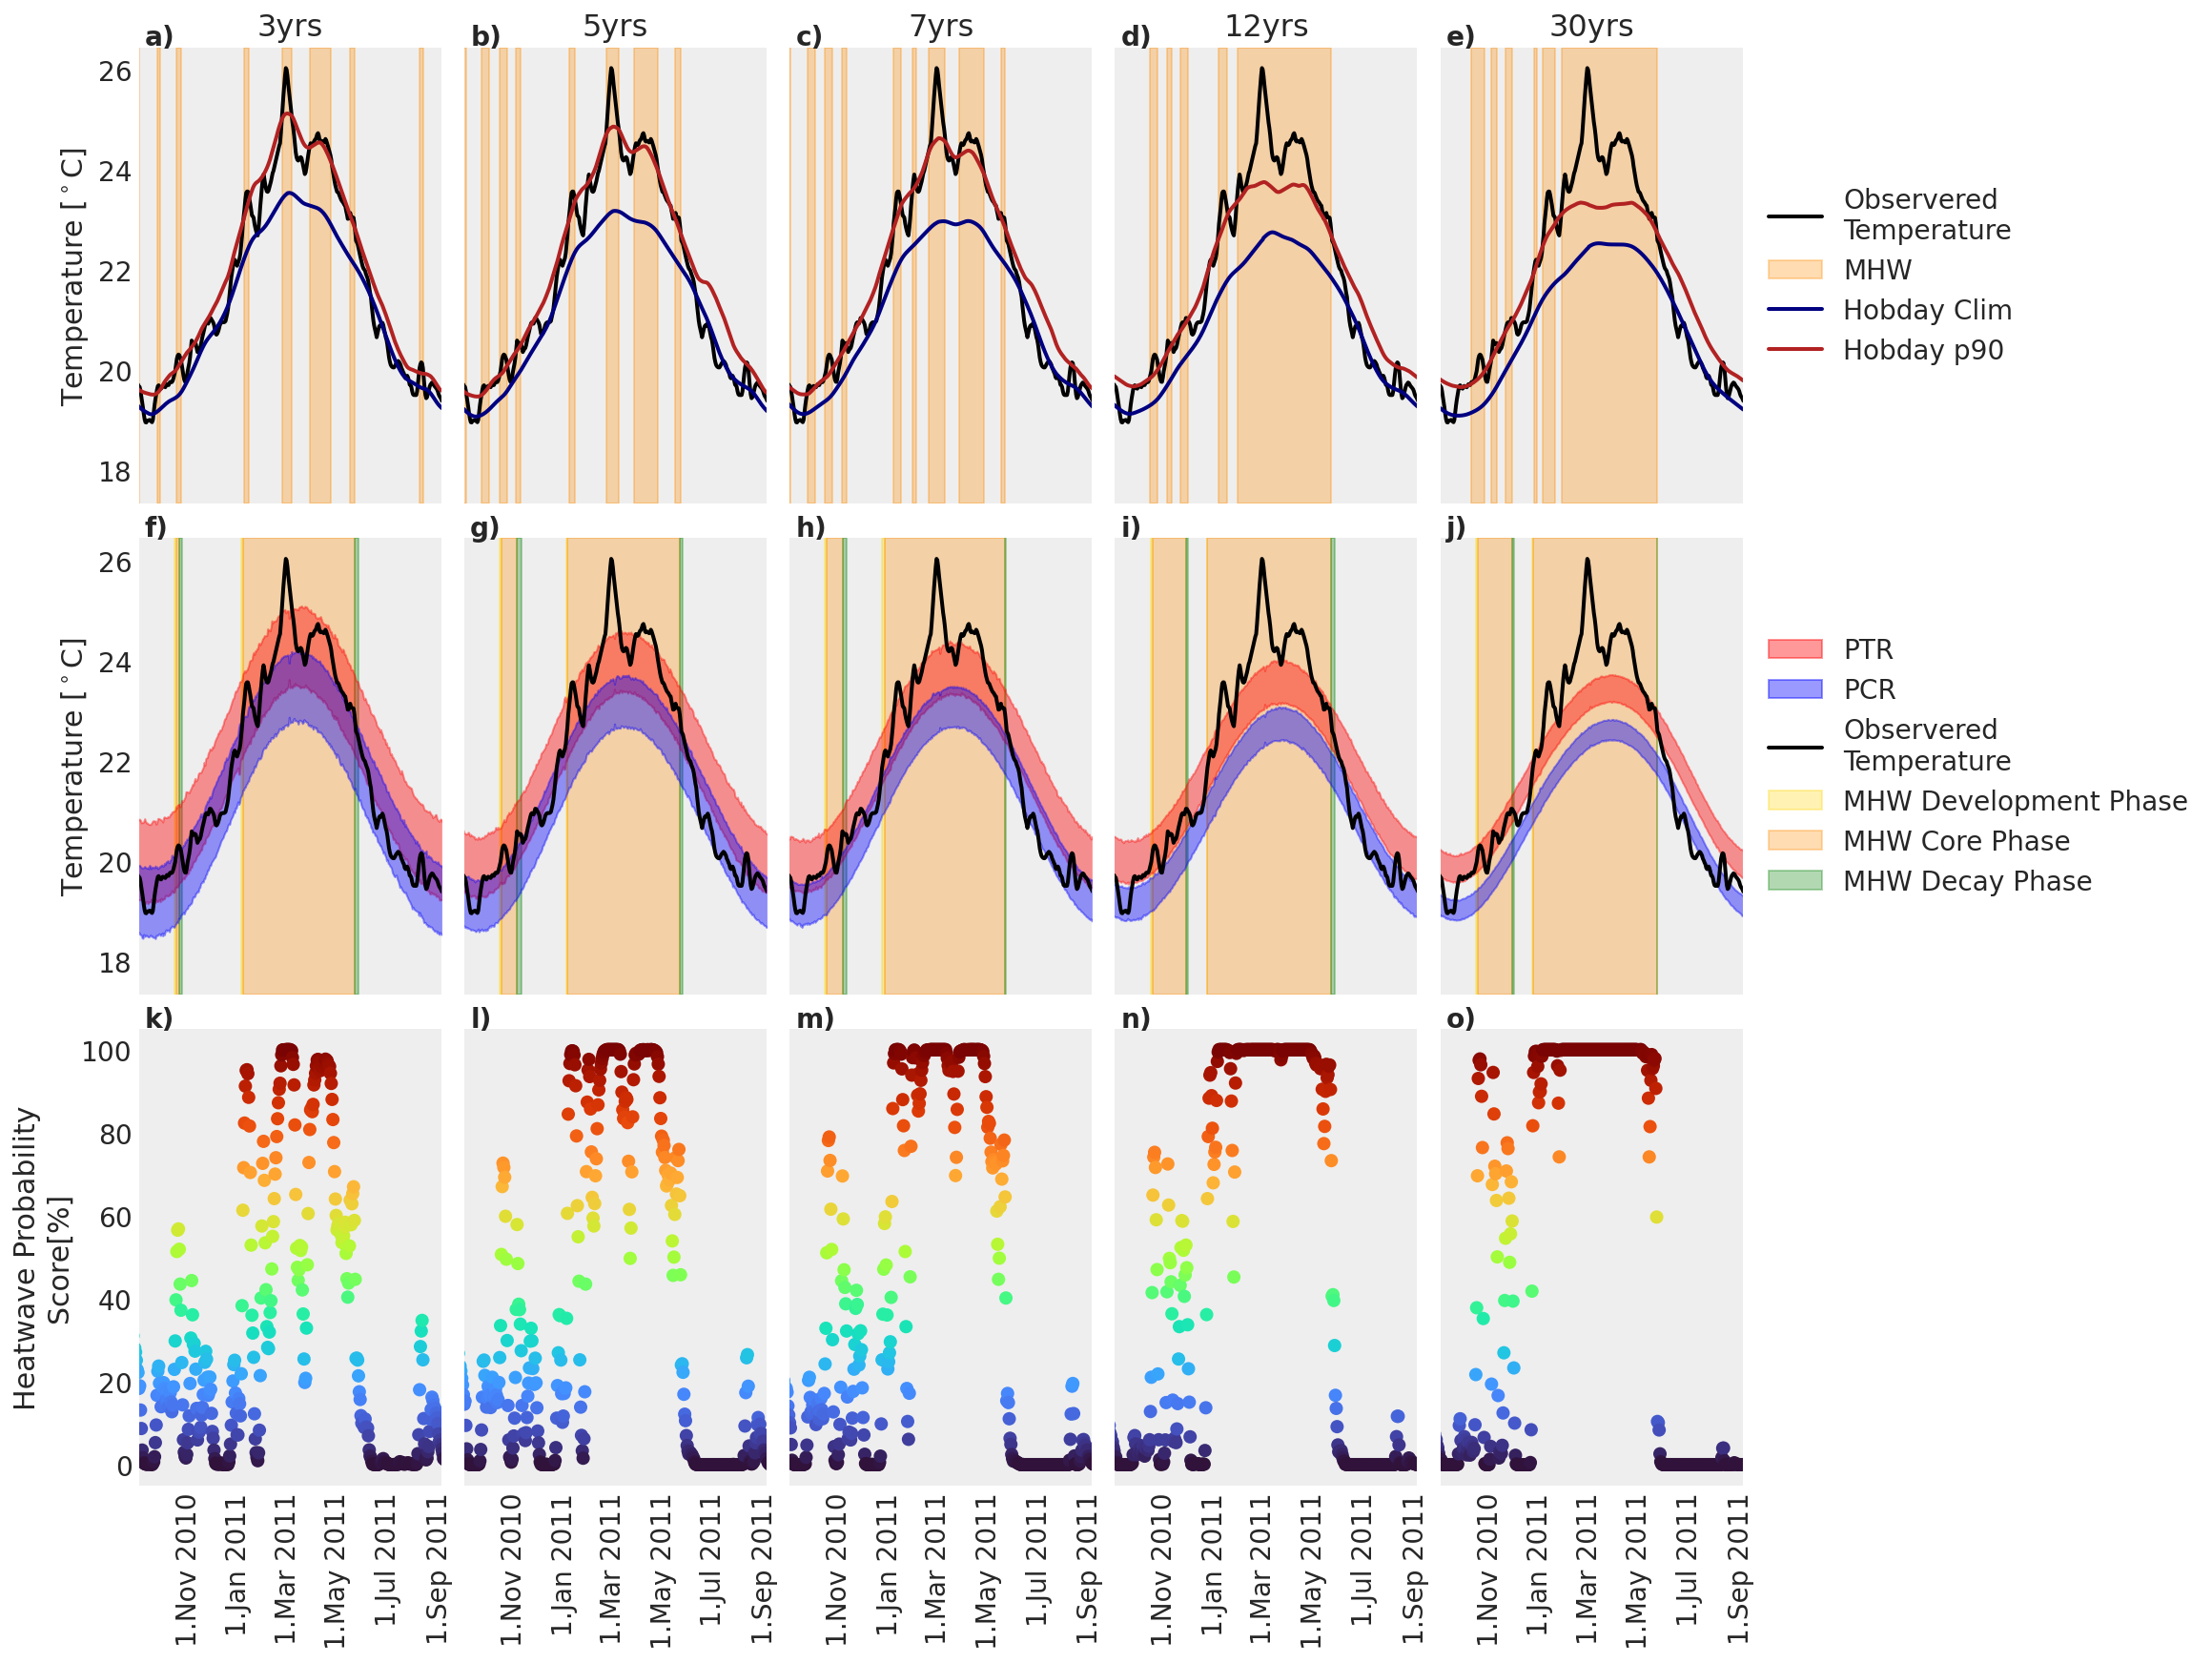

From 2010-09-02 to 2011-09-03


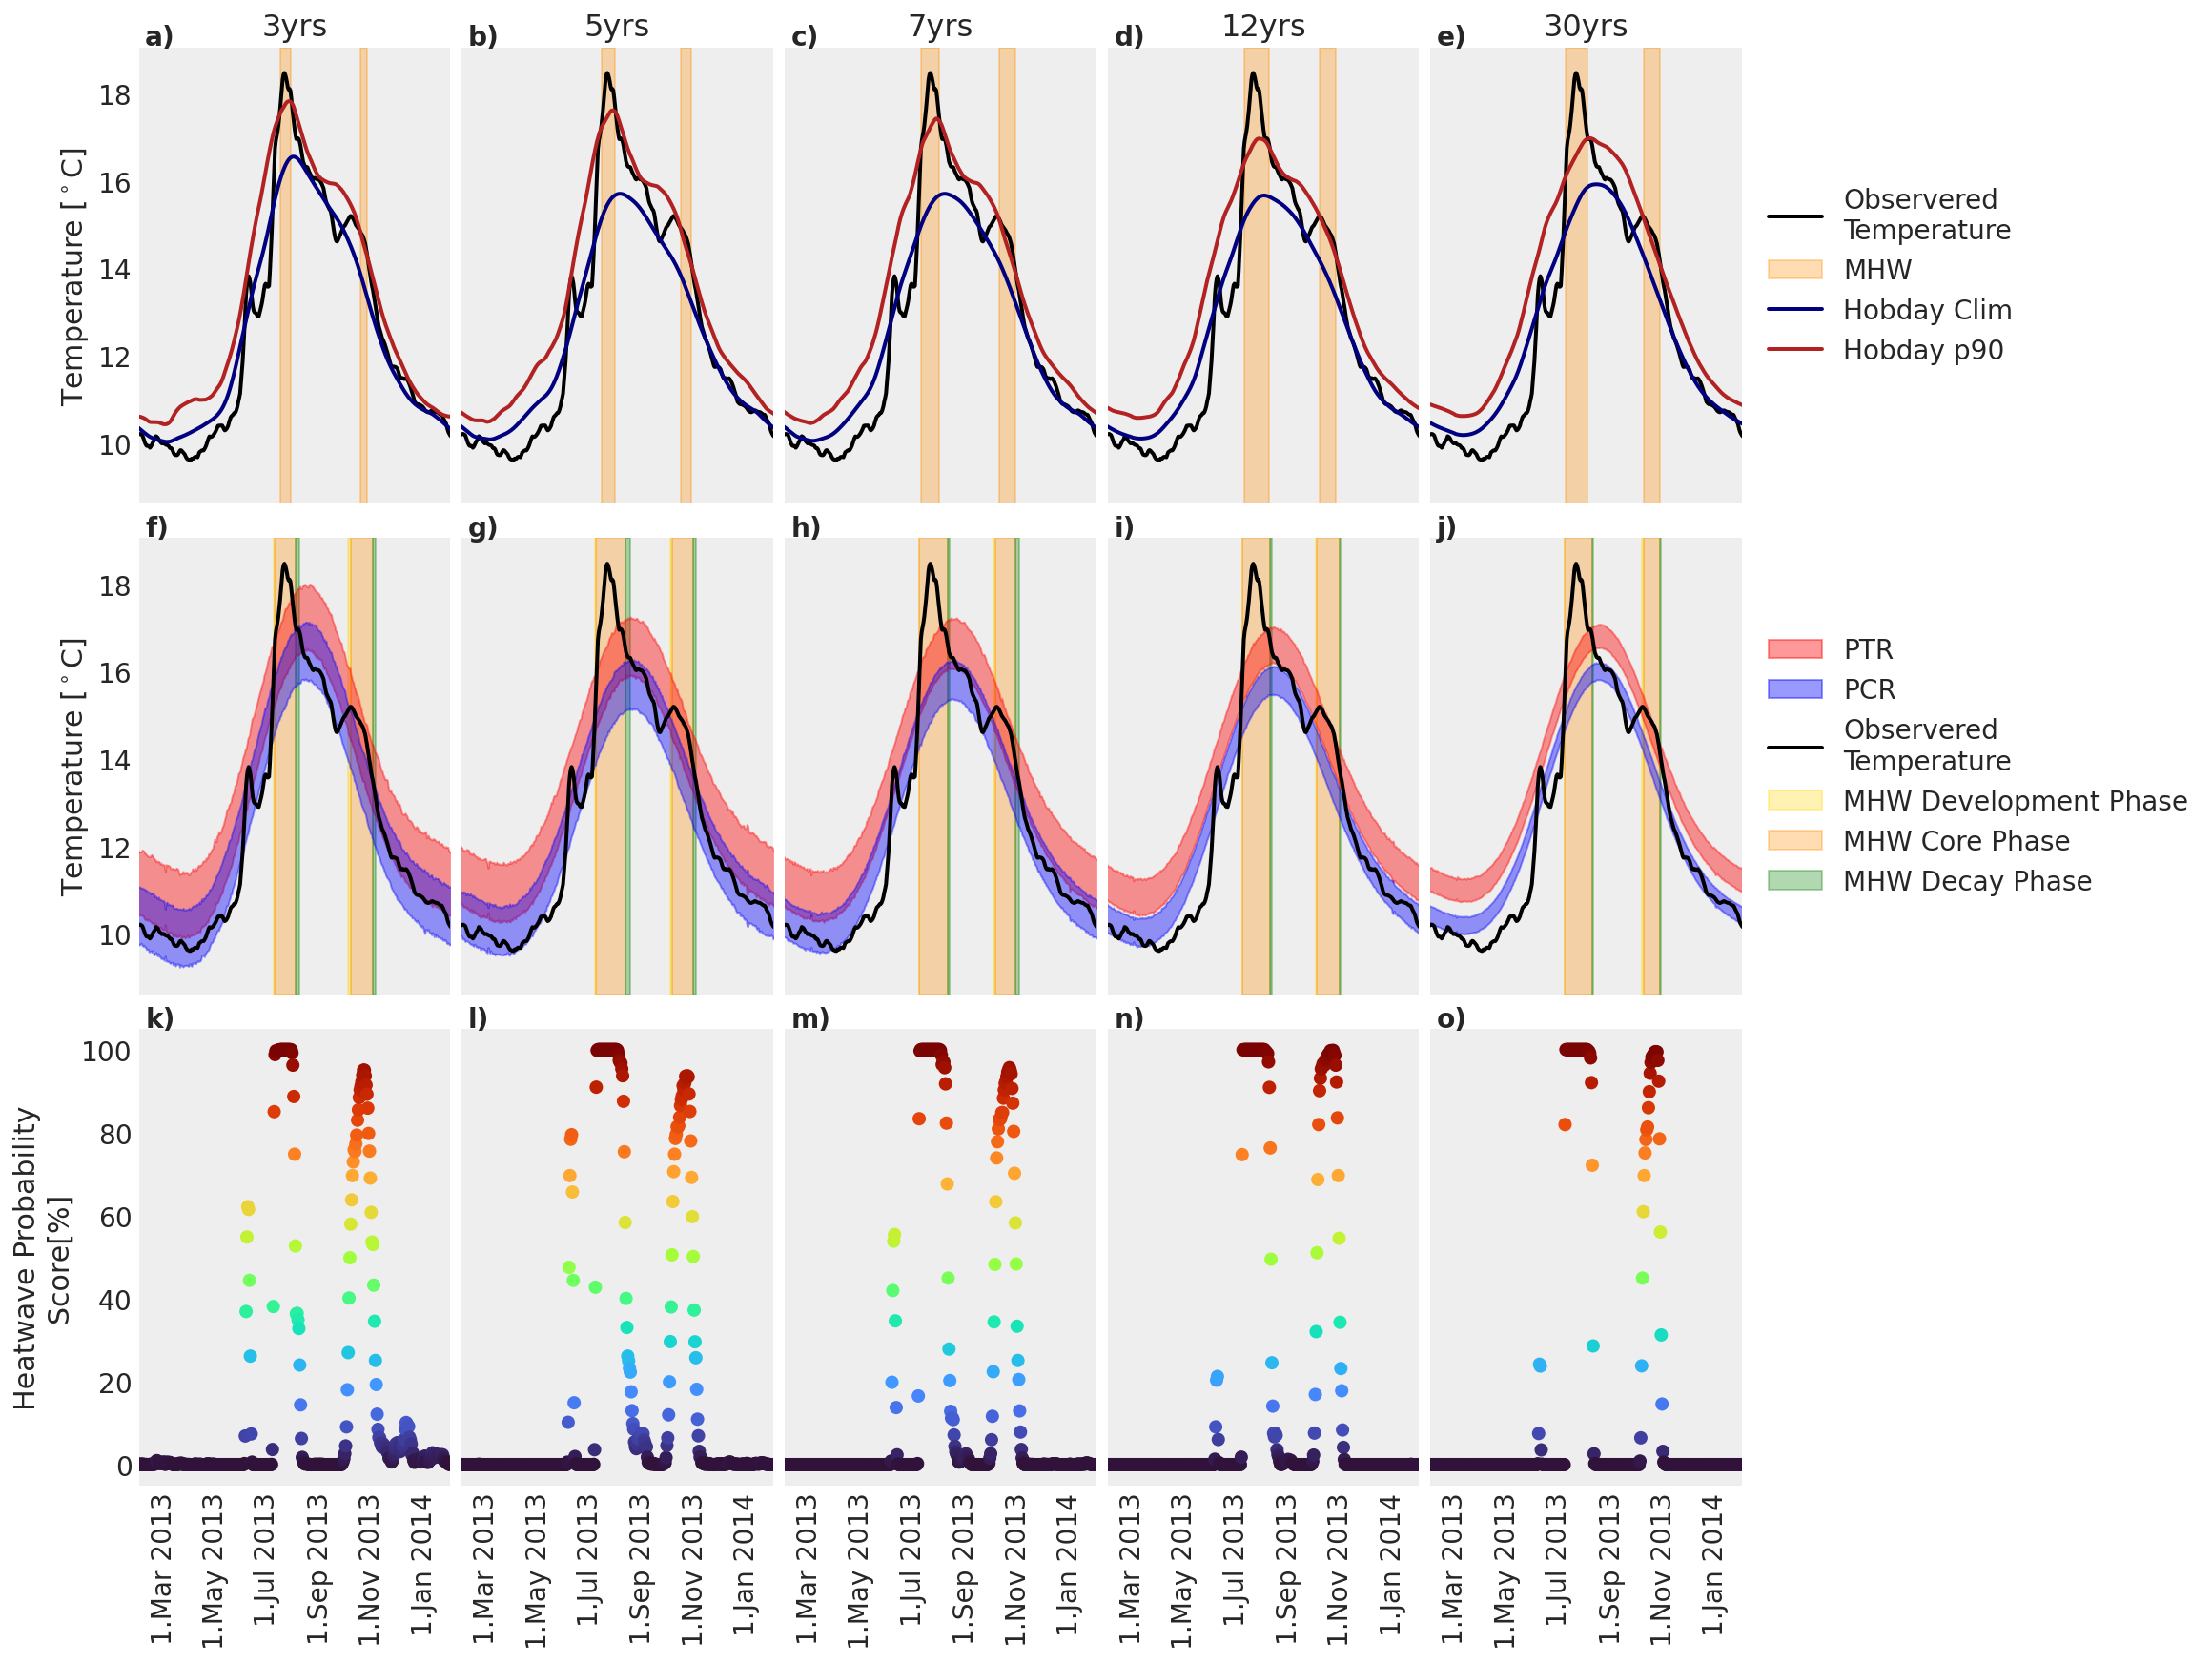

From 2013-01-31 to 2014-02-01


In [13]:

for i, site in enumerate(sites[:]):
    
    output_dir_site = os.path.join(figures_folder, site)

    # load Hobday climatology (30yrs reference)
    hobday = pd.read_csv( os.path.join(output_dir_site, "Daily_Hobday.csv"),index_col=0, parse_dates=True)
    mhw_dict_hobday_full = np.load(f"{output_dir_site}/30years_mhw_dict.npy",allow_pickle='TRUE').item()


    
    selected_date = pd.to_datetime(date_of_interest[site])
    
    f = 0
    fig, axs = plt.subplots(ncols = 5, nrows =3,  figsize=(16, 12) ,sharey='row', sharex = True  )
    axs = axs.flatten()
    
    axs[0].set_ylabel('Temperature [$^\\circ$C]')
    axs[5].set_ylabel('Temperature [$^\\circ$C]')
    axs[10].set_ylabel('Heatwave Probability\nScore[%]')


    for sub in subsets[:]:
        
        

        # load your OG timeseries for this subset
        og_timeseries = pd.read_pickle(f"{output_dir_site}/df_C_roll_{sub}yrs.pkl")
        
        
        # load inference data for this subset
        idata = az.from_netcdf(os.path.join(output_dir_site, f"Idata_eps_{sub}yrs.nc"))


        # calculate PCR & PTR and HPS
        PCR, PTR, time_array = get_PCRs_and_PTR(idata, og_timeseries)
        prob_PTR = calculate_prob_PTR(og_timeseries, PTR, variable="Temp")
    
        ax = axs[f]
        ax.set_title(f'{sub}yrs')
        
        
        if sub != str(30):
            ax.plot(og_timeseries.index, og_timeseries.Temp, label = 'Observered\nTemperature', color = 'black', lw =2)
            mhw_small,clim_small,  timearray_small = comparing_to_Hobday(og_timeseries.Temp)
            
            for ds_start,ds_end in zip(mhw_small['date_start'][:-1],mhw_small['date_end'][:-1]):
                ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
            ax.axvspan(pd.Timestamp(mhw_small['date_start'][-1]), pd.Timestamp(mhw_small['date_end'][-1]), color='darkorange', alpha=0.3,label = 'MHW')
            ax.plot(og_timeseries.index, clim_small['seas'], color = 'navy', lw = 2, ls ='-', label= 'Hobday Clim - subset')
            ax.plot(og_timeseries.index, clim_small['thresh'], color = 'firebrick', lw = 2, ls ='-', label= 'Hobday p90 - subset')
            
                

        else:
            
            
            
            ax.plot(og_timeseries.index, og_timeseries.Temp, label = 'Observered\nTemperature', color = 'black', lw =2)
            # Plot detected MHW in short and long hobday clim and threshold
            for ds_start,ds_end in zip(mhw_dict_hobday_full['date_start'][:-1],mhw_dict_hobday_full['date_end'][:-1]):
                ax.axvspan(pd.Timestamp(ds_start), pd.Timestamp(ds_end), color='darkorange', alpha=0.3)
            ax.axvspan(pd.Timestamp(mhw_dict_hobday_full['date_start'][-1]), pd.Timestamp(mhw_dict_hobday_full['date_end'][-1]), color='darkorange', alpha=0.3,label = 'MHW')
            ax.plot(hobday.index, hobday.seas, color = 'navy', lw = 2, label= 'Hobday Clim')
            ax.plot(hobday.index, hobday.thresh, color = 'firebrick', lw = 2, label= 'Hobday p90')

            mhw_small,clim_small,  timearray_small = comparing_to_Hobday(og_timeseries.Temp)
            # ax.plot(og_timeseries.index, clim_small['seas'], color = 'navy', lw = 2, ls ='--', label= 'Hobday Clim - subset')
            # ax.plot(og_timeseries.index, clim_small['thresh'], color = 'firebrick', lw = 2, ls ='--', label= 'Hobday p90 - subset')
        
            

        
        
        
        
        
        
        
        ax = axs[f+5]
        plot_probs_range(PTR,time_array, ax, color = 'red', label = 'PTR', mean_line = False)
        plot_probs_range(PCR,time_array, ax, color = 'blue', label = 'PCR', mean_line = False)
        
        mhw_dict_hps = detect_mhws_from_hps(HPS=np.array(prob_PTR),T_obs=og_timeseries.Temp,PCR=PCR, PTR=PTR , 
                                            time=og_timeseries.index,detection_threshold=50,ramp_threshold=20, 
                                            max_dip=10,min_duration=10)
        plot_mhw_phases(og_timeseries.Temp, np.array(prob_PTR), mhw_dict_hps, ax, detection_threshold=50, ramp_threshold=20)
        
      
        ax = axs[f+10]
        f += 1    
        ## --- Plot Exceendence Probability Score of
        ax.scatter(time_array, prob_PTR, c = prob_PTR, cmap = 'turbo')
       
            
      
        

        

    
    
    date_format = mdates.DateFormatter('1.%b %Y')  # On Windows use '%#d.%b'
    month_locator = mdates.MonthLocator(interval=2)   
    
    
    
    
    ax.set_xlim(selected_date - pd.Timedelta(days=180),  selected_date + pd.Timedelta(days=186))
    
    
    for ax in axs[:]:
        ax.xaxis.set_major_locator(month_locator)
        ax.xaxis.set_major_formatter(date_format)
        ax.tick_params(axis='x', rotation=90)  # Optional: rotate for better readability
        ax.grid()              
           
    
    
   

    ncols = 5
    nrows = 3
    
    # List of subplot indices where you want legends
    legend_axes_indices = [(row + 1) * ncols - 1 for row in range(nrows)]  # last in each row
    
    for idx in legend_axes_indices:
        ax = axs[idx]
        handles, labels = ax.get_legend_handles_labels()
    
        if handles:  # only if legend entries exist
            ax.legend(
                handles, labels,
                loc="center left",
                bbox_to_anchor=(1.05, 0.5),  # outside to the right
                borderaxespad=0,
                frameon=False
            )

    # generate subplot labels: a), b), c), ...
    labels = [f"{ch})" for ch in string.ascii_lowercase[:len(axs.flat)]]
    
    for ax, lab in zip(axs.flat, labels):
        ax.text(0.02, 1.05, lab,
                transform=ax.transAxes,
                fontsize=14,
                fontweight='bold',
                va='top', ha='left',
                bbox=dict(facecolor='white', alpha=0.0, edgecolor='none', pad=0))


        
    plt.savefig(os.path.join(output_dir_site, f"Figure_08.png"), dpi=300)
    plt.savefig(os.path.join(output_dir_site, f"Figure_08.pdf"), dpi=300)

    
    
    plt.show()
    # plt.close()

    print('From ' + str(selected_date - pd.Timedelta(days=180))[:10] +  ' to ' + str(selected_date + pd.Timedelta(days=186))[:10])